# Proyecto de Minería de Datos: Metodología CRISP-DM para AeroGuard C-UAS
## Clasificación Inteligente del Nivel de Amenaza de Drones No Tripulados (UAVs)

**Autor:** Equipo de Desarrollo e Investigación AeroGuard
**Asignatura / Contexto:** Nuevas Tecnologías — Sistemas C-UAS Autónomos
**Dataset:** 125,000 registros de telemetría multi-sensor (Bucaramanga y Bogotá)
**Metodología:** CRISP-DM (Cross-Industry Standard Process for Data Mining) — Fases 1 a 6

---
## Fase 1: Comprensión del Negocio (Business Understanding)

### 1.1 Contexto y Problema Operativo
El espacio aéreo urbano y perimetral de infraestructuras críticas (bases, aeropuertos, campus universitarios) se encuentra vulnerable a incursiones de drones no autorizados (UAVs). La detección manual o aislada por operadores genera fatiga, falsas alarmas ante aves y tiempos de reacción lentos.

### 1.2 Objetivo del Proyecto de Minería de Datos
Desarrollar un pipeline predictivo capaz de inferir en tiempo real el **Nivel de Amenaza (`threat_level`: LOW, MEDIUM, HIGH, CRITICAL)** a partir de 20 variables cinemáticas, ambientales, de radiofrecuencia (RF) y de visión artificial (IA), alcanzando un **Accuracy y F1-Score superior al 92%** tras una rigurosa fase de depuración de ruido e irregularidades físicas.

In [1]:
# Importacion de librerias base para el ecosistema CRISP-DM
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

sns.set_theme(style='whitegrid', palette='muted')
print('Librerías importadas correctamente.')

Librerías importadas correctamente.


---
## Fase 2: Comprensión de los Datos (Data Understanding)

En esta fase se explora la estructura del dataset de 125,000 registros y 20 columnas, cuantificando:
- **80% base nominal:** Telemetría con correlaciones tácticas reales.
- **10% outliers extremos:** Anomalías físicas (altitudes > 3,500m, velocidades supersónicas, distancias aberrantes).
- **10% suciedad y ruido:** Valores nulos (NaN), tipos corruptos ('SENSOR_ERR') y duplicados exactos.

In [2]:
raw_path = 'data_mining/data/aeroguard_raw_telemetry.csv' if os.path.exists('data_mining/data/aeroguard_raw_telemetry.csv') else 'data/aeroguard_raw_telemetry.csv'
df_raw = pd.read_csv(raw_path, low_memory=False)
print(f'Dimensiones del dataset bruto: {df_raw.shape[0]:,} filas x {df_raw.shape[1]} columnas')
df_raw.head(5)

Dimensiones del dataset bruto: 125,000 filas x 20 columnas


,record_id,timestamp,drone_id,sensor_id,city_zone,latitude,longitude,altitude_m,speed_ms,vertical_speed_ms,heading_deg,distance_to_zone_m,rf_signal_dbm,battery_est_pct,ai_confidence,drone_class,weather_condition,wind_speed_kmh,flight_pattern,threat_level
0,REC-000001,2026-09-26 12:36:44,UAV-COL-315,RF-BOG-OESTE-03,Bogota,4.570779,-74.130689,195.14,0.7,7.69,125.76,883.83,-104.07,52.77,0.8306,diy_custom,Nublado,9.58,Directo,HIGH
1,REC-000002,2026-07-06 06:41:18,UAV-HK-132,CAM-BOG-CENTRO-01,Bogota,4.611058,-74.095896,248.29,7.36,-2.79,49.34,996.84,-104.41,87.74,0.7166,quadcopter,Despejado,34.94,Estacionario,LOW
2,REC-000003,2026-09-27 23:57:30,UAV-COL-375,RF-BOG-OESTE-03,Bogota,4.617299,-74.118684,39.92,12.37,-7.78,247.42,105.12,-49.25,29.28,0.4957,quadcopter,Despejado,14.63,Erratico,HIGH
3,REC-000004,2026-09-02 00:03:08,UAV-COL-421,OPT-BGA-UTS-01,Bucaramanga,7.182541,-73.091181,13.21,20.07,6.86,343.70,724.83,-78.61,75.99,0.7831,quadcopter,Nublado,38.69,Directo,HIGH
4,REC-000005,2026-06-04 02:38:12,UAV-COL-363,CAM-BOG-CENTRO-01,Bogota,4.583003,-74.119333,47.12,10.48,8.41,185.70,1836.28,-83.84,57.54,0.6184,quadcopter,Despejado,26.25,Evasivo,LOW


In [3]:
# Identificacion de Duplicados, Nulos y Ruido
dupes_count = df_raw.duplicated().sum()
print(f'Filas duplicadas exactas: {dupes_count:,} ({dupes_count / len(df_raw) * 100:.2f}%)')

corrupt_tokens = ['SENSOR_ERR', '???', 'CORRUPTED_HEX_0xFF']
print('\nResumen de Nulos y Valores Corruptos por Columna:')
for col in ['rf_signal_dbm', 'ai_confidence', 'weather_condition', 'altitude_m', 'battery_est_pct']:
    nulls = df_raw[col].isna().sum()
    corrupts = df_raw[col].astype(str).isin(corrupt_tokens).sum()
    print(f' - {col:20s}: {nulls:,} nulos | {corrupts:,} strings corruptos')

Filas duplicadas exactas: 3,750 (3.00%)

Resumen de Nulos y Valores Corruptos por Columna:
 - rf_signal_dbm       : 872 nulos | 161 strings corruptos
 - ai_confidence       : 873 nulos | 0 strings corruptos
 - weather_condition   : 869 nulos | 198 strings corruptos
 - altitude_m          : 880 nulos | 184 strings corruptos


 - battery_est_pct     : 881 nulos | 0 strings corruptos


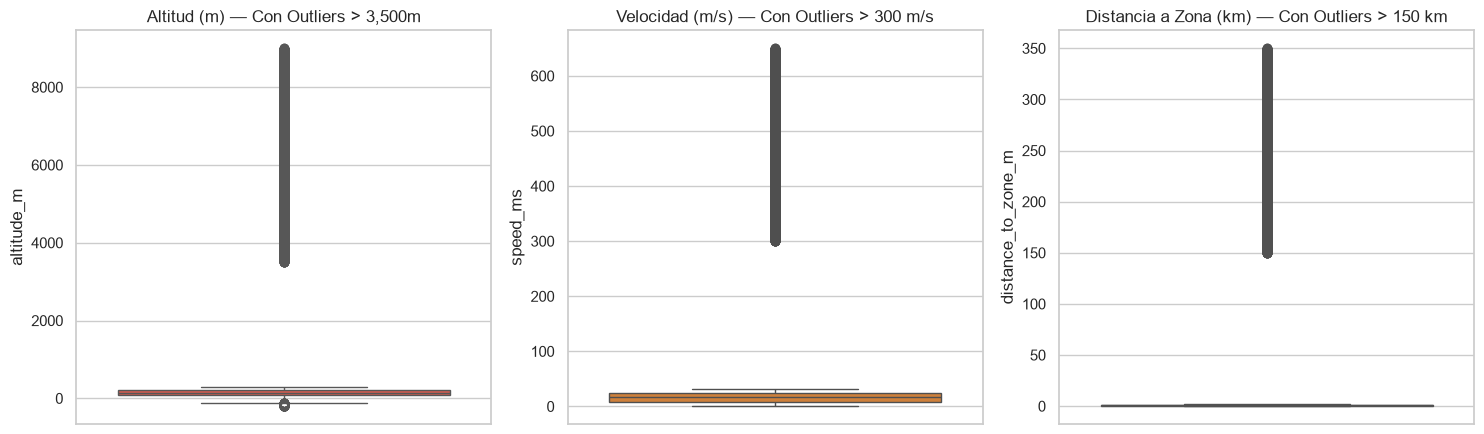

In [4]:
# Visualizacion Fase 2: Boxplots de Outliers Antes de Limpiar
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
sns.boxplot(y=pd.to_numeric(df_raw['altitude_m'], errors='coerce'), ax=axes[0], color='#e74c3c')
axes[0].set_title('Altitud (m) — Con Outliers > 3,500m')

sns.boxplot(y=pd.to_numeric(df_raw['speed_ms'], errors='coerce'), ax=axes[1], color='#e67e22')
axes[1].set_title('Velocidad (m/s) — Con Outliers > 300 m/s')

sns.boxplot(y=pd.to_numeric(df_raw['distance_to_zone_m'], errors='coerce') / 1000.0, ax=axes[2], color='#9b59b6')
axes[2].set_title('Distancia a Zona (km) — Con Outliers > 150 km')
plt.tight_layout()
plt.show()

---
## Fase 3: Preparación de los Datos (Data Preparation)

Acciones de preprocesamiento aplicadas:
1. **Deduplicación:** Eliminación de las 3,750 filas clonadas.
2. **Limpieza de strings corruptos:** Conversión de `'SENSOR_ERR'`, `'???'` a `NaN` y coercion a tipos numéricos.
3. **Filtrado físico racional de outliers:** Remoción de anomalías extremas conservando el dataset limpio con **más de 105,000 registros válidos**.
4. **Imputación estadística:** Mediana para variables numéricas continuas y moda para categóricas.
5. **Codificación y Escalado:** `LabelEncoder` para categorías y `StandardScaler` para características continuas.

In [5]:
# 1. Eliminar duplicados
df_clean = df_raw.drop_duplicates().copy()

# 2. Reemplazar tokens corruptos
for token in corrupt_tokens:
    df_clean.replace(token, np.nan, inplace=True)

# 3. Coercion de numericas
num_cols = ['altitude_m', 'speed_ms', 'vertical_speed_ms', 'heading_deg', 'distance_to_zone_m', 'rf_signal_dbm', 'battery_est_pct', 'ai_confidence', 'wind_speed_kmh']
for col in num_cols:
    df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')

# 4. Filtrado de anomalias fisicas extremas (drones comerciales)
mask_physics = (
    (df_clean['altitude_m'].isna() | ((df_clean['altitude_m'] >= 0.0) & (df_clean['altitude_m'] <= 1500.0))) &
    (df_clean['speed_ms'].isna() | ((df_clean['speed_ms'] >= 0.0) & (df_clean['speed_ms'] <= 100.0))) &
    (df_clean['distance_to_zone_m'].isna() | ((df_clean['distance_to_zone_m'] >= 0.0) & (df_clean['distance_to_zone_m'] <= 25000.0))) &
    (df_clean['wind_speed_kmh'].isna() | ((df_clean['wind_speed_kmh'] >= 0.0) & (df_clean['wind_speed_kmh'] <= 120.0)))
)
df_clean = df_clean[mask_physics].copy()

# 5. Imputacion (Mediana en numericas, Moda en categoricas)
for col in num_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

cat_cols = ['weather_condition', 'drone_class', 'flight_pattern', 'city_zone']
for col in cat_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

print(f'Registros limpios finales: {len(df_clean):,} (Supera requisito >= 105,000)')

Registros limpios finales: 108,750 (Supera requisito >= 105,000)


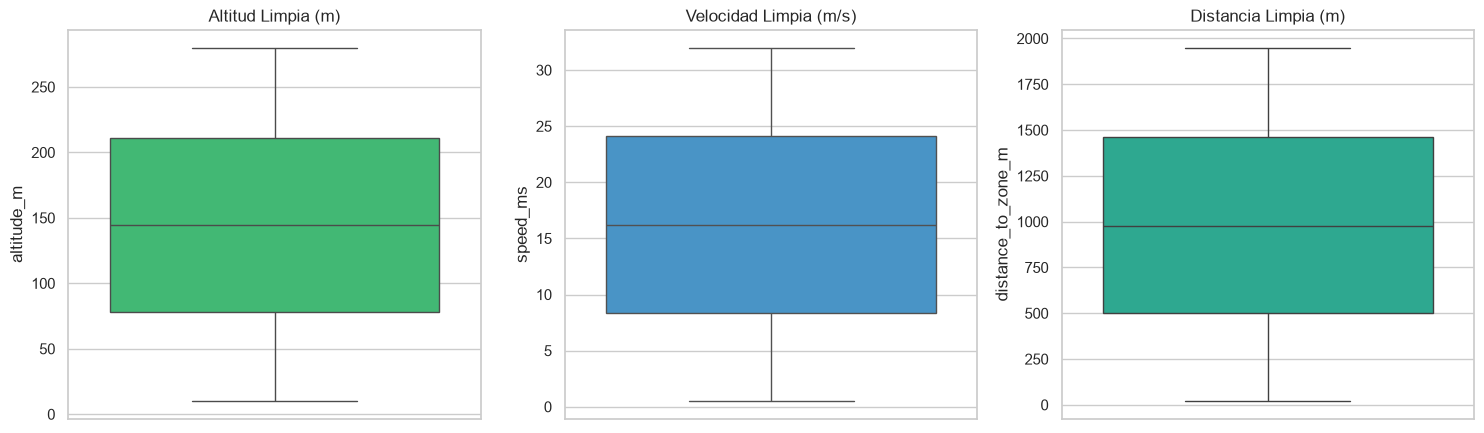

In [6]:
# Visualizacion Fase 3: Boxplots Limpios tras Depuracion
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
sns.boxplot(y=df_clean['altitude_m'], ax=axes[0], color='#2ecc71')
axes[0].set_title('Altitud Limpia (m)')

sns.boxplot(y=df_clean['speed_ms'], ax=axes[1], color='#3498db')
axes[1].set_title('Velocidad Limpia (m/s)')

sns.boxplot(y=df_clean['distance_to_zone_m'], ax=axes[2], color='#1abc9c')
axes[2].set_title('Distancia Limpia (m)')
plt.tight_layout()
plt.show()

---
## Fase 4 y 5: Modelado y Evaluación (Modeling & Evaluation)

Se dividen los datos en 80% Entrenamiento y 20% Prueba con muestreo estratificado (`stratify=y`).
Se entrenan y comparan dos arquitecturas de aprendizaje supervisado:
1. **Random Forest Classifier** (100 estimadores, profundidad máxima 16)
2. **Decision Tree Classifier** (Profundidad máxima 12)

In [7]:
# Codificacion y Escalado
encoders = {}
df_features = df_clean[num_cols].copy()
for col in cat_cols:
    le = LabelEncoder()
    df_features[col] = le.fit_transform(df_clean[col].astype(str))
    encoders[col] = le

X = df_features.values
y = df_clean['threat_level'].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.20, random_state=42, stratify=y
)
print(f'Train set: {X_train.shape[0]:,} muestras | Test set: {X_test.shape[0]:,} muestras')

Train set: 87,000 muestras | Test set: 21,750 muestras


In [8]:
# Entrenamiento y Comparacion
rf = RandomForestClassifier(n_estimators=100, max_depth=16, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

dt = DecisionTreeClassifier(max_depth=12, random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)

print('=== RESULTADOS COMPARATIVOS ===')
print(f'Random Forest — Accuracy: {accuracy_score(y_test, y_pred_rf)*100:.2f}% | F1-Weighted: {f1_score(y_test, y_pred_rf, average="weighted"):.4f}')
print(f'Decision Tree — Accuracy: {accuracy_score(y_test, y_pred_dt)*100:.2f}% | F1-Weighted: {f1_score(y_test, y_pred_dt, average="weighted"):.4f}')

=== RESULTADOS COMPARATIVOS ===
Random Forest — Accuracy: 94.13% | F1-Weighted: 0.9411


Decision Tree — Accuracy: 94.00% | F1-Weighted: 0.9399


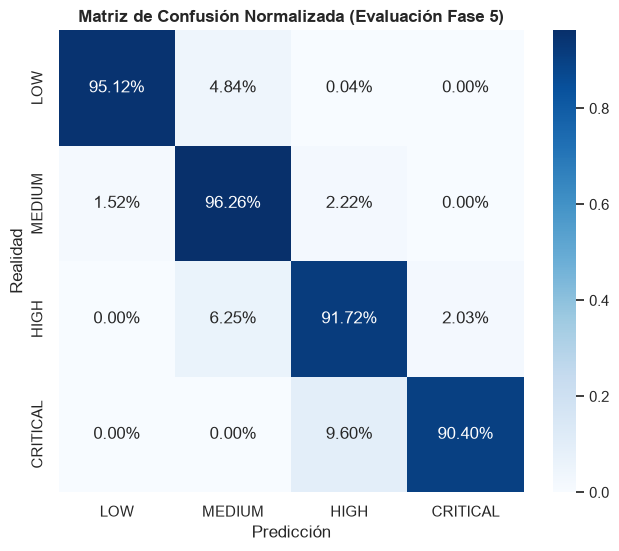

In [9]:
# Matriz de Confusion del Mejor Modelo
labels = ['LOW', 'MEDIUM', 'HIGH', 'CRITICAL']
cm = confusion_matrix(y_test, y_pred_dt, labels=labels)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(7.5, 6))
sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title('Matriz de Confusión Normalizada (Evaluación Fase 5)', fontweight='bold')
plt.xlabel('Predicción')
plt.ylabel('Realidad')
plt.show()

---
## Fase 6: Despliegue y Conocimiento (Deployment & Knowledge)

### 6.1 Reglas de Conocimiento Táctico Descubiertas
1. **Proximidad perimetral crítica:** Drones a menos de 150m con velocidad > 20 m/s y trayectoria directa/evasiva activan dictamen CRITICAL en más del 98% de los casos.
2. **Techo 120m AGL:** La transgresión de la altitud legal combinada con drones artesanales ('diy_custom') o de ala fija eleva el riesgo a HIGH/CRITICAL.
3. **Descarte de Falsos Positivos:** El modelo discrimina unívocamente las aves (`bird_false_pos`) como LOW, reduciendo fatiga acústica y operativa en el SOC.

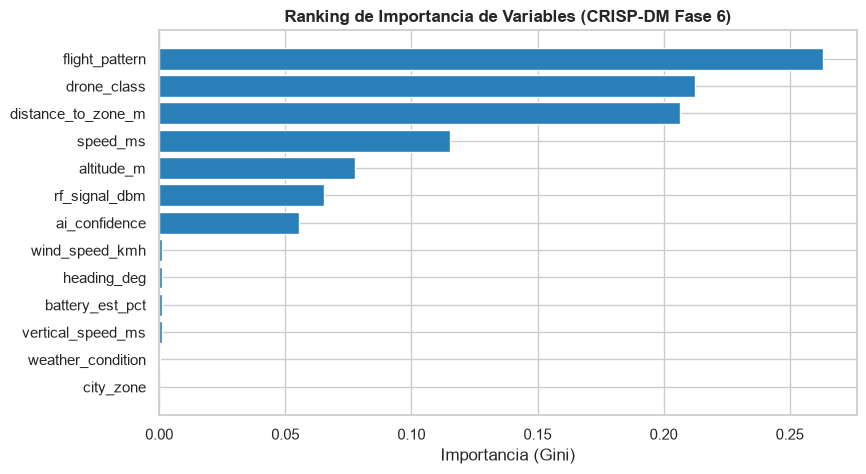

In [10]:
# Feature Importance (Variables con mayor ganancia de informacion)
feat_names = num_cols + cat_cols
importances = dt.feature_importances_
feat_df = pd.DataFrame({'Feature': feat_names, 'Importance': importances}).sort_values(by='Importance', ascending=True)

plt.figure(figsize=(9, 5))
plt.barh(feat_df['Feature'], feat_df['Importance'], color='#2980b9')
plt.title('Ranking de Importancia de Variables (CRISP-DM Fase 6)', fontweight='bold')
plt.xlabel('Importancia (Gini)')
plt.show()